# AI651 – Deep Learning for Space, Time and Graphs
# Assignment 3

Syed Obaidullah Hassan Chishti - 25280049

## Question 2 — Which way is the slowdown moving?

# Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt

N = 40 

# Question 2 - Which way is the slowdown moving?

## Part (a) - A symmetric layer and what it cannot do

In [2]:
# Single-spike snapshot and its correct next snapshot
x = np.zeros(N); x[20] = 1.0
true_next = np.roll(x, -1)                       

# Features for the least-squares fit: [x_i, x_{i-1} + x_{i+1}]
f_self  = x
f_neigh = np.roll(x, 1) + np.roll(x, -1)
Phi = np.stack([f_self, f_neigh], axis=1)        # shape (40, 2)

(a, b), *_ = np.linalg.lstsq(Phi, true_next, rcond=None)
residual = Phi @ np.array([a, b]) - true_next

print(f"Fitted a = {a:.4f}, b = {b:.4f}")
print(f"Residual sum of squared errors = {residual @ residual:.4f}")

Fitted a = 0.0000, b = 0.5000
Residual sum of squared errors = 0.5000


### (ii) Apply the fitted layer to a wider bump

In [3]:
i = np.arange(N)
bump0 = np.exp(-((i - 20) ** 2) / 8)

def symmetric_step(v, a, b):
    return a * v + b * (np.roll(v, 1) + np.roll(v, -1))

steps = 20
model_seq = [bump0.copy()]
true_seq  = [bump0.copy()]

vm = bump0.copy()
vt = bump0.copy()
for _ in range(steps):
    vm = symmetric_step(vm, a, b); model_seq.append(vm.copy())
    vt = np.roll(vt, -1);          true_seq.append(vt.copy())

model_seq = np.array(model_seq)   # (21, 40)
true_seq  = np.array(true_seq)

print("Model bump peak at t=20 -> sensor", int(model_seq[-1].argmax()),
      "(value", round(model_seq[-1].max(), 3), ")")
print("True  bump peak at t=20 -> sensor", int(true_seq[-1].argmax()),
      "(value", round(true_seq[-1].max(), 3), ")")

Model bump peak at t=20 -> sensor 20 (value 0.405 )
True  bump peak at t=20 -> sensor 0 (value 1.0 )


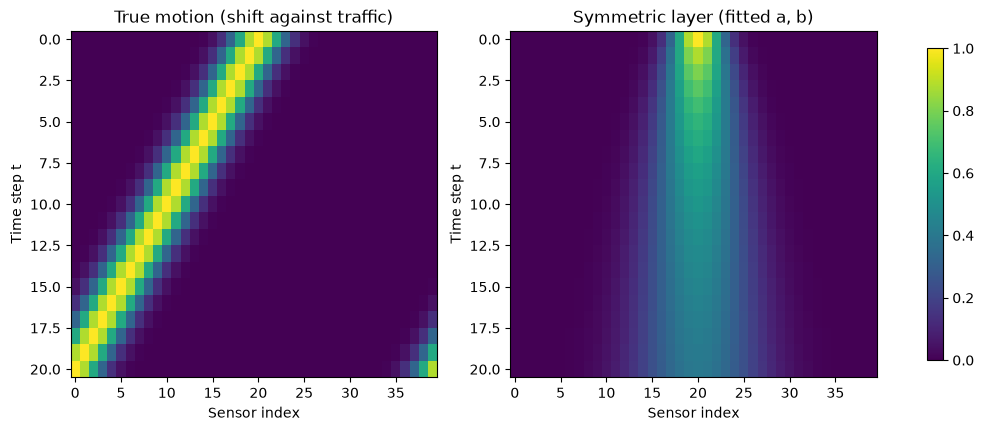

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
vmin, vmax = 0.0, 1.0

im0 = axes[0].imshow(true_seq, aspect="auto", cmap="viridis", vmin=vmin, vmax=vmax)
axes[0].set(title="True motion (shift against traffic)",
            xlabel="Sensor index", ylabel="Time step t")

im1 = axes[1].imshow(model_seq, aspect="auto", cmap="viridis", vmin=vmin, vmax=vmax)
axes[1].set(title="Symmetric layer (fitted a, b)",
            xlabel="Sensor index", ylabel="Time step t")

fig.colorbar(im1, ax=axes, shrink=0.9)

import os
os.makedirs("figures", exist_ok=True)
fig.savefig("figures/q2a_heatmaps.png", dpi=150, bbox_inches="tight")
plt.show()

## Part (b) - Fix 1: weight the two directions separately

In [5]:
a_b, w_minus, w_plus = 0.0, 0.0, 1.0

rng = np.random.default_rng(0)
exact = True
for _ in range(1000):
    v = rng.normal(size=N)                      # any snapshot
    pred = a_b * v + w_minus * np.roll(v, 1) + w_plus * np.roll(v, -1)
    if not np.allclose(pred, np.roll(v, -1)):   # correct next snapshot
        exact = False

print("a, w_-, w_+ =", (a_b, w_minus, w_plus))
print("Exact next snapshot for every input:", exact)
print("1D kernel on [x_{i-1}, x_i, x_{i+1}] =", [w_minus, a_b, w_plus])
print("Ring boundary: use circular (wrap-around) padding, i.e. np.roll")

a, w_-, w_+ = (0.0, 0.0, 1.0)
Exact next snapshot for every input: True
1D kernel on [x_{i-1}, x_i, x_{i+1}] = [0.0, 0.0, 1.0]
Ring boundary: use circular (wrap-around) padding, i.e. np.roll


## Part (c) - Fix 2: use history, keep the neighbour weights equal

In [6]:
A, B, C = 0.0, 1.0, -1.0

exact_back = True
for _ in range(1000):
    v_prev = rng.normal(size=N)
    v_cur  = np.roll(v_prev, -1)        # backward: x(t) = roll(x(t-1), -1)
    v_next = np.roll(v_cur, -1)         # correct next snapshot

    pred = A*v_cur + B*(np.roll(v_cur, 1) + np.roll(v_cur, -1)) + C*v_prev
    if not np.allclose(pred, v_next):
        exact_back = False

print("a, b, c =", (A, B, C))
print("Exact for backward motion on every input:", exact_back)

a, b, c = (0.0, 1.0, -1.0)
Exact for backward motion on every input: True


In [7]:
exact_fwd = True
for _ in range(1000):
    v_prev = rng.normal(size=N)
    v_cur  = np.roll(v_prev, 1)         # forward: x(t) = roll(x(t-1), +1)
    v_next = np.roll(v_cur, 1)          # correct next snapshot (forward)

    pred = A*v_cur + B*(np.roll(v_cur, 1) + np.roll(v_cur, -1)) + C*v_prev
    if not np.allclose(pred, v_next):
        exact_fwd = False

print("Same a, b, c =", (A, B, C))
print("Exact for forward motion on every input:", exact_fwd)

Same a, b, c = (0.0, 1.0, -1.0)
Exact for forward motion on every input: True
